# NN_L6_learning_curve

**Test macro-F1 on the Financial PhraseBank against the number of labelled sentences (TF-IDF, mean word2vec, embedding bag random or word2vec start), and against the embedding dimension.**

Neural Networks and Deep Learning (NN), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L6/NN_L6_learning_curve/NN_L6_learning_curve.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Pre-trained vectors and the label budget.

tfidf_lr, 169 sentences = 51.0   [curve.tfidf_lr.p5]
w2v_lr, 169 sentences = 48.0   [curve.w2v_lr.p5]
embbag, 169 sentences = 47.2   [curve.embbag.p5]
embbag_w2v, 169 sentences = 51.0   [curve.embbag_w2v.p5]


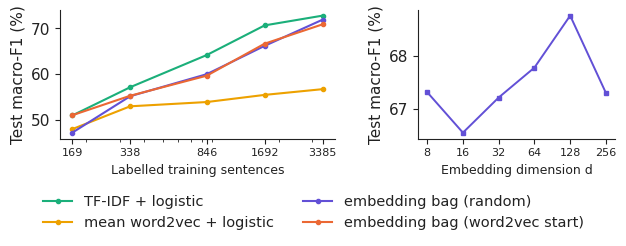

In [3]:
import json, urllib.request
_F = 'learning_curve_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L6/NN_L6_learning_curve/' + _F))
FR = [0.05, 0.1, 0.25, 0.5, 1.0]; n = [int(f * R['ntr']) for f in FR]
cur = {k: [100 * np.mean([f for s, fr, f in R[k] if fr == x]) for x in FR] for k in ['tfidf_lr', 'w2v_lr', 'embbag', 'embbag_w2v']}
for k in cur: show(f'curve.{k}.p5', f'{k}, {n[0]} sentences', round(cur[k][0], 1))
fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.5), gridspec_kw={'width_ratios': [1.4, 1]})
for k, c, l in [('tfidf_lr', PAL['benchmark'], 'TF-IDF + logistic'), ('w2v_lr', PAL['alt'], 'mean word2vec + logistic'), ('embbag', '#6250d6', 'embedding bag (random)'), ('embbag_w2v', PAL['model'], 'embedding bag (word2vec start)')]:
    axes[0].plot(n, cur[k], marker='o', ms=3, color=c, lw=1.5, label=l)
axes[0].set_xscale('log'); axes[0].set_xticks(n); axes[0].set_xticklabels([str(x) for x in n], fontsize=8); axes[0].set_xlabel('Labelled training sentences', fontsize=9); axes[0].set_ylabel('Test macro-F1 (%)')
d = sorted(R['dims'], key=int); axes[1].plot([int(x) for x in d], [100 * np.mean(R['dims'][x]) for x in d], marker='s', ms=3, color='#6250d6'); axes[1].set_xscale('log', base=2)
axes[1].set_xticks([int(x) for x in d]); axes[1].set_xticklabels(d, fontsize=8); axes[1].set_xlabel('Embedding dimension d', fontsize=9); axes[1].set_ylabel('Test macro-F1 (%)')
legend_bottom(fig, ncol=2); fig.tight_layout(rect=(0, .2, 1, 1))
fig.savefig('learning_curve.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()